In [10]:
from Bio import SeqIO
import matplotlib.pyplot as plt
import numpy as np

In [31]:
########################################
# rRNA参数
########################################

CONFIG = {

"18S": {
"files":[
"rRNA_18S.osaTOath.aln.fa",
"rRNA_18S.slyTOath.aln.fa",
"rRNA_18S.zmaTOath.aln.fa",
"rRNA_18S.garTOath.aln.fa"
],
"window":50,
"step":10
},

"5.8S": {
"files":[
"rRNA_5_8S.osaTOath.aln.fa",
"rRNA_5_8S.slyTOath.aln.fa",
"rRNA_5_8S.zmaTOath.aln.fa",
"rRNA_5_8S.garTOath.aln.fa"
],
"window":20,
"step":10
},
   
"28S": {
"files":[
"rRNA_28S.osaTOath.aln.fa",
"rRNA_28S.slyTOath.aln.fa",
"rRNA_28S.zmaTOath.aln.fa",
"rRNA_28S.garTOath.aln.fa"
],
"window":50,
"step":10
}

}


species=["osa","sly","zma","gar"]
colors={
"osa":"firebrick",
"sly":"royalblue",
"zma":"darkgreen",
"gar":"darkorange"
}

In [32]:
########################################
# 读取pairwise MSA
########################################
def read_aln(f):
    recs=list(SeqIO.parse(f,"fasta"))
    return str(recs[0].seq).upper(),str(recs[1].seq).upper()

########################################
# sliding window divergence
########################################
def sliding(ref,query,w,s):
    L=len(ref)
    xs=[]
    ys=[]

    for i in range(0,L-w+1,s):
        r=ref[i:i+w]
        q=query[i:i+w]
        diff=sum(
            1 for a,b in zip(r,q)
            if a!=b
        )
        xs.append(i+w/2)
        ys.append(diff/w)
    return np.array(xs),np.array(ys),L

In [35]:
########################################
# 计算所有rRNA
########################################
all_results=[]
widths=[]

for rRNA,info in CONFIG.items():
    curves=[]
    L_ref=None
    for f in info["files"]:
        sp=f.split(".")[1].split("TO")[0]
        ref,qry=read_aln(f)
        x,y,L=sliding(
            ref,
            qry,
            info["window"],
            info["step"]
        )
        curves.append((sp,x,y))
        L_ref=L

    widths.append(L_ref)
    all_results.append((rRNA,curves,L_ref,info))

Done.


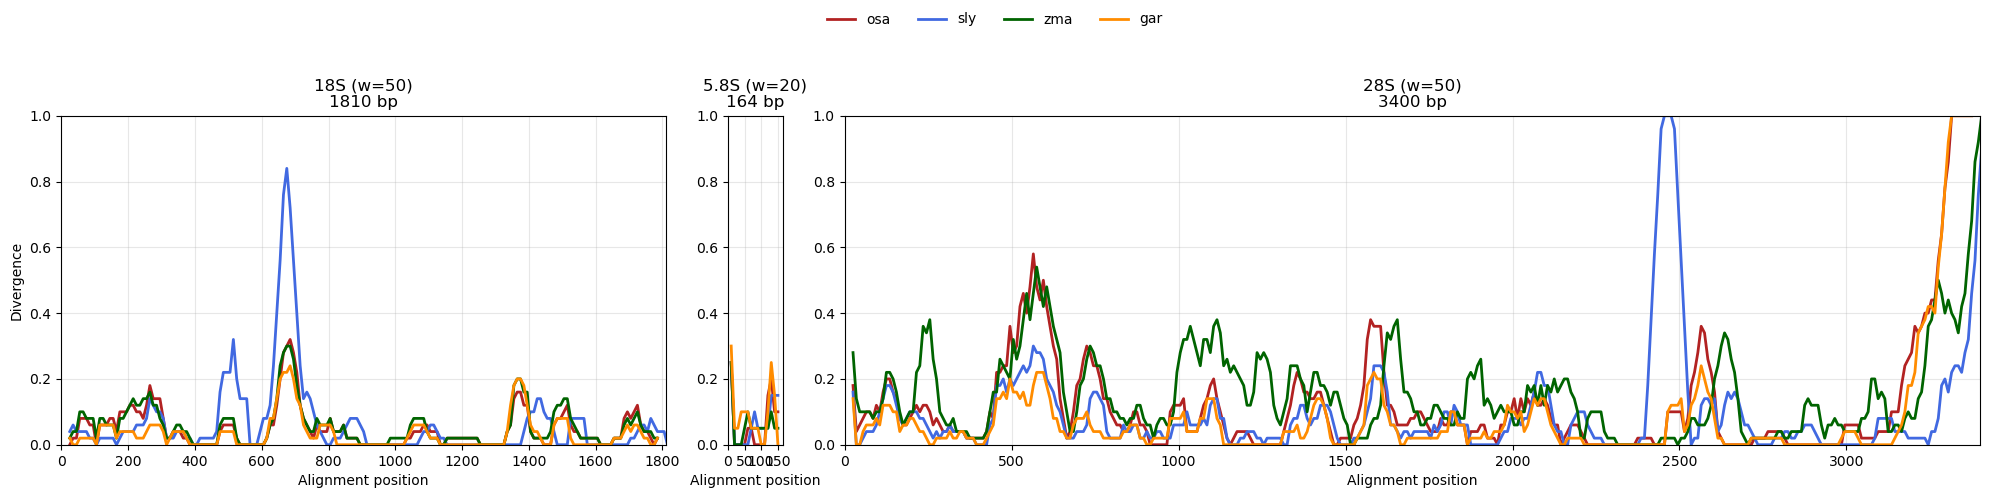

In [34]:
########################################
# 画图
########################################
fig,axes=plt.subplots(
    1,3,
    figsize=(20,5),
    gridspec_kw={"width_ratios":widths}
)

for ax,(name,curves,L,info) in zip(
    axes,all_results
):

    for sp,x,y in curves:

        ax.plot(
            x,y,
            lw=2,
            color=colors[sp],
            label=sp
        )

    ax.set_title(
        f"{name} (w={info['window']})\n{L} bp"
    )

    ax.set_xlim(0,L)
    ax.set_ylim(0,1)

    ax.grid(alpha=0.3)

    ax.set_xlabel("Alignment position")
    step_tick = 50 if L<300 else 200 if L<2500 else 500

    ax.set_xticks(np.arange(0,L+1,step_tick))

axes[0].set_ylabel("Divergence")

handles,labels=axes[0].get_legend_handles_labels()

fig.legend(
    handles,labels,
    loc="upper center",
    ncol=4,
    frameon=False
)

plt.tight_layout(rect=[0,0,1,0.88])

plt.savefig(
"rRNA_divergence.pdf",
dpi=300,bbox_inches="tight"
)

print("Done.")